In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

import Settings as cfg
from utils.postprocess_claims import (
    create_reasoning_claims,
)


In [2]:
# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path(cfg.__file__).resolve().parent.parent

DATA_SPLIT_DIR = Path(cfg.DATA_SPLIT_DIR)
LLM_RESULTS_DIR = Path(cfg.LLM_RESULTS_ROOT)

REASONING_DIR = Path(
    getattr(
        cfg,
        "REASONING_ROOT",
        PROJECT_ROOT / "Reasoning",
    )
)

EVALUATION_DIR = PROJECT_ROOT / "outputs" / "evaluation"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

EVALUATION_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# ML model Performance

In [3]:
def calculate_metrics(df, model_name):

    y_true = df["Actual_Group"]
    y_pred = df["Predicted_Group"]

    # Confusion matrix with AD as positive class
    # Order: CN = negative, AD = positive
    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=["CN", "AD"],
    ).ravel()

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    precision = precision_score(
        y_true,
        y_pred,
        pos_label="AD",
        zero_division=0,
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        pos_label="AD",
        zero_division=0,
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label="AD",
        zero_division=0,
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1_Score": f1,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
    }

In [4]:
logistic_df = pd.read_csv(cfg.ML_MODEL_OUTPUT_ROOT / "logistic/test_predictions.csv")
xgboost_df = pd.read_csv(cfg.ML_MODEL_OUTPUT_ROOT / "XgBoost/test_predictions.csv")

In [5]:
results = [
    calculate_metrics(
        logistic_df,
        "Logistic Regression",
    ),
    calculate_metrics(
        xgboost_df,
        "XGBoost",
    ),
]

In [6]:
metrics_df = pd.DataFrame(results)

In [7]:
percentage_columns = [
    "Accuracy",
    "Precision",
    "Sensitivity",
    "Specificity",
    "F1_Score",
]

metrics_df[percentage_columns] = (
    metrics_df[percentage_columns]
    * 100
).round(2)

In [8]:
display(metrics_df)

,Model,Accuracy,Precision,Sensitivity,Specificity,F1_Score,TP,TN,FP,FN
0,Logistic Regression,87.3,83.87,89.66,85.29,86.67,26,29,5,3
1,XGBoost,87.3,86.21,86.21,88.24,86.21,25,30,4,4


In [9]:
MODEL_ORDER = [
    "gpt-5.4",
    "grok-4.20-reasoning",
]

MODEL_LABELS = {
    "gpt-5.4": "GPT5.4",
    "grok-4.20-reasoning": "Grok4.2",
}

METHOD_ORDER = [
    "zero_shot",
    "random",
    "cosine",
    "euclidean",
    "delta_knn",
    "lr_weighted_xgboost_path_gain", 
]

METHOD_LABELS = {
    "zero_shot": "Zero-Shot",
    "random": "Random",
    "cosine": "Cosine",
    "euclidean": "Euclidean",
    "delta_knn": "Delta-KNN",
    "lr_weighted_xgboost_path_gain": "Proposed",
    "zero_shot": "Zero-Shot",
}

METHOD_RANK = {
    method: index
    for index, method in enumerate(
        METHOD_ORDER
    )
}

In [10]:
test_df = pd.read_csv(
    DATA_SPLIT_DIR / "test.csv"
)

labels_df = (
    test_df[["Subject", "Group"]]
    .copy()
    .rename(columns={"Group": "Correct_Label"})
)

train_df = pd.read_csv(
    DATA_SPLIT_DIR / "train.csv"
)


In [11]:
def read_result_file(csv_path):

    df = pd.read_csv(
        csv_path,
        dtype={"Subject": str},
    )

    required_columns = {
        "Subject",
        "Prediction",
    }

    missing_columns = (
        required_columns
        - set(df.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{csv_path} is missing required columns: "
            f"{sorted(missing_columns)}"
        )

    method = csv_path.parent.name
    model = csv_path.parent.parent.name
    shot = csv_path.parent.parent.parent.name

    match_run = re.fullmatch(
        r"run_(\d+)",
        csv_path.stem,
    )

    if not match_run:
        print(
            f"Skipping unexpected filename: "
            f"{csv_path.name}"
        )
        return None

    run = int(
        match_run.group(1)
    )

    result_df = (
        df[
            [
                "Subject",
                "Prediction",
            ]
        ]
        .copy()
    )

    result_df["Subject"] = (
        result_df["Subject"]
        .astype(str)
        .str.strip()
    )

    result_df["Prediction"] = (
        result_df["Prediction"]
        .astype(str)
        .str.strip()
        .str.upper()
    )

    result_df["Shot"] = shot
    result_df["Method"] = method
    result_df["Model"] = model
    result_df["Run"] = run

    result_df = result_df.merge(
        labels_df,
        on="Subject",
        how="left",
        validate="many_to_one",
    )

    if result_df["Correct_Label"].isna().any():

        missing_subjects = (
            result_df.loc[
                result_df["Correct_Label"].isna(),
                "Subject",
            ]
            .tolist()
        )

        raise ValueError(
            "Ground-truth labels were not found for: "
            f"{missing_subjects}"
        )

    result_df = result_df[
        [
            "Shot",
            "Method",
            "Model",
            "Run",
            "Subject",
            "Correct_Label",
            "Prediction",
        ]
    ]

    return result_df

In [12]:
all_results = []

for csv_path in sorted(
    LLM_RESULTS_DIR.glob(
        "*/*/*/run_*.csv"
    )
):

    result_df = read_result_file(
        csv_path
    )

    if result_df is not None:
        all_results.append(
            result_df
        )

if not all_results:
    raise FileNotFoundError(
        "No LLM result files were found under: "
        f"{LLM_RESULTS_DIR}\n"
        "Expected structure: "
        "<shot>/<model>/<method>/run_*.csv"
    )

In [13]:
combined_df = pd.concat(
    all_results,
    ignore_index=True,
)

combined_df = (
    combined_df
    .sort_values(
        by=[
            "Shot",
            "Model",
            "Method",
            "Run",
            "Subject",
        ]
    )
    .reset_index(drop=True)
)

output_file = (
    EVALUATION_DIR
    / "all_predictions.csv"
)

combined_df.to_csv(
    output_file,
    index=False,
)


# Majority Voting Performance
For each model and example-selection method, the final prediction is obtained by majority vote across the three repeated LLM runs. Accuracy, precision, sensitivity, specificity, and F1-score are then calculated against the fixed test labels.

In [14]:
valid_labels = {"AD", "CN"}

invalid_df = combined_df[~combined_df["Prediction"].isin(valid_labels)]

if not invalid_df.empty:
    print("Invalid predictions found:")
    print(
        invalid_df[
            ["Method", "Model", "Run", "Subject", "Prediction"]
        ]
    )
    raise ValueError("Some predictions are not AD or CN.")

In [15]:
vote_df = (
    combined_df
    .pivot_table(
        index=[
            "Shot",
            "Method",
            "Model",
            "Subject",
            "Correct_Label",
        ],
        columns="Run",
        values="Prediction",
        aggfunc="first",
    )
    .reset_index()
)

vote_df = vote_df.rename(
    columns={
        1: "Run_1",
        2: "Run_2",
        3: "Run_3",
    }
)


In [16]:
required_run_columns = [
    "Run_1",
    "Run_2",
    "Run_3",
]

missing_run_columns = [
    column
    for column in required_run_columns
    if column not in vote_df.columns
]

if missing_run_columns:
    raise ValueError(
        "Missing run columns: "
        f"{missing_run_columns}"
    )

In [17]:
vote_df = vote_df.dropna(
    subset=[
        "Run_1",
        "Run_2",
        "Run_3",
    ]
).reset_index(drop=True)

In [18]:
run_cols = ["Run_1", "Run_2", "Run_3"]

missing_runs = vote_df[vote_df[run_cols].isna().any(axis=1)]

if not missing_runs.empty:
    print("Subjects with missing runs:")
    print(missing_runs)

    raise ValueError("Some subjects do not have all 3 predictions.")

In [19]:
def majority_vote(row):

    predictions = [
        row["Run_1"],
        row["Run_2"],
        row["Run_3"],
    ]

    counts = pd.Series(
        predictions
    ).value_counts()

    return counts.index[0]


vote_df["Majority_Prediction"] = (
    vote_df.apply(
        majority_vote,
        axis=1,
    )
)

In [20]:
metric_rows = []

for (
    shot,
    method,
    model,
), group in vote_df.groupby(
    [
        "Shot",
        "Method",
        "Model",
    ]
):

    y_true = group[
        "Correct_Label"
    ]

    y_pred = group[
        "Majority_Prediction"
    ]

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    precision = precision_score(
        y_true,
        y_pred,
        pos_label="AD",
        average="binary",
        zero_division=0,
    )

    sensitivity = recall_score(
        y_true,
        y_pred,
        pos_label="AD",
        average="binary",
        zero_division=0,
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label="AD",
        average="binary",
        zero_division=0,
    )

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[
            "CN",
            "AD",
        ],
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    metric_rows.append({
        "Shot": shot,
        "Method": method,
        "Model": model,
        "Accuracy": accuracy,
        "Precision": precision,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "F1_Score": f1,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
    })


majority_metrics_df = pd.DataFrame(
    metric_rows
)

In [21]:
shot_order = [
    "0-shot",
    "2-shot",
    "4-shot",
]

majority_metrics_df["Shot"] = pd.Categorical(
    majority_metrics_df["Shot"],
    categories=shot_order,
    ordered=True,
)

majority_metrics_df["Method"] = pd.Categorical(
    majority_metrics_df["Method"],
    categories=METHOD_ORDER,
    ordered=True,
)

majority_metrics_df["Model"] = pd.Categorical(
    majority_metrics_df["Model"],
    categories=MODEL_ORDER,
    ordered=True,
)

majority_metrics_df = (
    majority_metrics_df
    .sort_values(
        by=[
            "Shot",
            "Model",
            "Method",
        ]
    )
    .reset_index(drop=True)
)

In [22]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.expand_frame_repr", False)
print(majority_metrics_df)

      Shot                         Method                Model  Accuracy  Precision  Sensitivity  Specificity  F1_Score  TP  TN  FP  FN
0   0-shot                      zero_shot              gpt-5.4  0.841270   0.851852     0.793103     0.882353  0.821429  23  30   4   6
1   0-shot                      zero_shot  grok-4.20-reasoning  0.682540   0.595745     0.965517     0.441176  0.736842  28  15  19   1
2   2-shot                         random              gpt-5.4  0.793651   0.766667     0.793103     0.794118  0.779661  23  27   7   6
3   2-shot                         cosine              gpt-5.4  0.730159   0.730769     0.655172     0.794118  0.690909  19  27   7  10
4   2-shot                      euclidean              gpt-5.4  0.873016   0.862069     0.862069     0.882353  0.862069  25  30   4   4
5   2-shot                      delta_knn              gpt-5.4  0.873016   0.888889     0.827586     0.911765  0.857143  24  31   3   5
6   2-shot  lr_weighted_xgboost_path_gain       

# Interpretability Evaluation
The following analyses evaluate prediction/reasoning consistency, brain-region coverage, reasoning directionality, a qualitative reasoning example, and explicit use of in-context examples.

In [23]:
# ---------------------------------------------------------
# Global figure settings
# ---------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

FONT_SIZE = 15


## 1. Consistency
Prediction consistency is assessed across the three repeated LLM runs. Reasoning consistency is taken from the GPT-4.1 consistency judge and categorized as CONSISTENT, PARTIALLY CONSISTENT, or CONTRADICTORY.

In [24]:
CONSISTENCY_DIR = REASONING_DIR / "Consistency"

In [25]:
def extract_classification(answer):

    if pd.isna(answer):
        return None

    text = str(
        answer
    ).strip()

    match = re.search(
        (
            r"Classification:\s*"
            r"(CONSISTENT|PARTIALLY CONSISTENT|CONTRADICTORY)"
        ),
        text,
        flags=re.IGNORECASE,
    )

    if match:

        return (
            match
            .group(1)
            .upper()
        )

    return None


# ============================================================
# LOAD CONSISTENCY RESULTS
# ============================================================

all_rows = []

for csv_path in sorted(
    CONSISTENCY_DIR.glob(
        "*/*.csv"
    )
):

    # Example:
    #
    # Consistency/
    # └── gpt-5.4/
    #     └── cosine.csv
    #
    # model  = gpt-5.4
    # method = cosine

    model = (
        csv_path
        .parent
        .name
    )

    method = (
        csv_path
        .stem
    )

    df = pd.read_csv(
        csv_path,
        dtype={
            "Subject": str
        },
    )

    required_columns = {
        "Subject",
        "Answer",
    }

    missing_columns = (
        required_columns
        - set(df.columns)
    )

    if missing_columns:

        print(
            f"Skipping {csv_path} - "
            f"missing columns: "
            f"{sorted(missing_columns)}"
        )

        continue

    # --------------------------------------------------------
    # Extract consistency category
    # --------------------------------------------------------

    df["classification"] = (
        df["Answer"]
        .apply(
            extract_classification
        )
    )

    # --------------------------------------------------------
    # Keep common columns
    # --------------------------------------------------------

    temp = pd.DataFrame({

        "model":
            model,

        "method":
            method,

        "subject":
            (
                df["Subject"]
                .astype(str)
                .str.strip()
            ),

        "classification":
            df["classification"],
    })

    all_rows.append(
        temp
    )


# ============================================================
# CHECK RESULTS
# ============================================================

if not all_rows:

    raise FileNotFoundError(
        "No reasoning-consistency files were found under: "
        f"{CONSISTENCY_DIR}\n"
        "Expected structure: "
        "<model>/<method>.csv"
    )


# ============================================================
# COMBINE
# ============================================================

combined_consistency = pd.concat(
    all_rows,
    ignore_index=True,
)


# ============================================================
# VALIDATE CLASSIFICATIONS
# ============================================================

missing_classification = (
    combined_consistency[
        "classification"
    ]
    .isna()
)

if missing_classification.any():

    print(
        "Warning: consistency classification "
        "could not be extracted for "
        f"{missing_classification.sum()} rows."
    )


# ============================================================
# SORT
# ============================================================

combined_consistency[
    "_model_order"
] = (
    combined_consistency[
        "model"
    ]
    .map({
        model: index
        for index, model
        in enumerate(
            MODEL_ORDER
        )
    })
)

combined_consistency[
    "_method_order"
] = (
    combined_consistency[
        "method"
    ]
    .map(
        METHOD_RANK
    )
)

combined_consistency = (
    combined_consistency
    .sort_values(
        by=[
            "_model_order",
            "_method_order",
            "subject",
        ]
    )
    .drop(
        columns=[
            "_model_order",
            "_method_order",
        ]
    )
    .reset_index(
        drop=True
    )
)

In [26]:
true_label_map = (
    test_df
    .assign(
        Subject=(
            test_df["Subject"]
            .astype(str)
            .str.strip()
        ),
        Group=(
            test_df["Group"]
            .astype(str)
            .str.strip()
            .str.upper()
        ),
    )
    .set_index(
        "Subject"
    )["Group"]
    .to_dict()
)


prediction_df = (
    combined_df[
        [
            "Model",
            "Method",
            "Run",
            "Subject",
            "Prediction",
        ]
    ]
    .copy()
    .rename(
        columns={
            "Model": "model",
            "Method": "method",
            "Run": "run",
            "Subject": "subject",
            "Prediction": "prediction",
        }
    )
)

prediction_df["subject"] = (
    prediction_df["subject"]
    .astype(str)
    .str.strip()
)

prediction_df["prediction"] = (
    prediction_df["prediction"]
    .astype(str)
    .str.strip()
    .str.upper()
)


In [27]:
consistency_rows = []

group_cols = ["model","method","subject"]

for (model,method,subject), subject_df in prediction_df.groupby(group_cols):

    run_predictions = (subject_df[["run","prediction"]].drop_duplicates().sort_values("run"))

    prediction_map = dict(zip(run_predictions["run"],run_predictions["prediction"]))
    predictions = (run_predictions["prediction"].dropna().tolist())

    true_label = true_label_map.get(str(subject).strip())
    unique_predictions = set(predictions)

    if len(unique_predictions) == 1:
        consistent_prediction = predictions[0]
        if consistent_prediction == true_label:
            prediction_status = ("Consistent Correct")
        else:
            prediction_status = ("Consistent Incorrect")
    else:
        consistent_prediction = None
        prediction_status = "Inconsistent"

    consistency_rows.append({
        "model": model,
        "method": method,
        "subject": subject,
        "true_label": true_label,
        "run_1_prediction": prediction_map.get(1),
        "run_2_prediction": prediction_map.get(2),
        "run_3_prediction": prediction_map.get(3),
        "consistent_prediction": consistent_prediction,
        "prediction_status":prediction_status})

prediction_consistency = pd.DataFrame(consistency_rows)

In [28]:
combined_analysis = prediction_consistency.merge(
    combined_consistency[["model","method","subject","classification"]],
    on=["model","method","subject"],how="inner")

In [29]:
combined_counts = (combined_analysis.groupby(["model","method","prediction_status","classification"]).size().reset_index(name="count"))

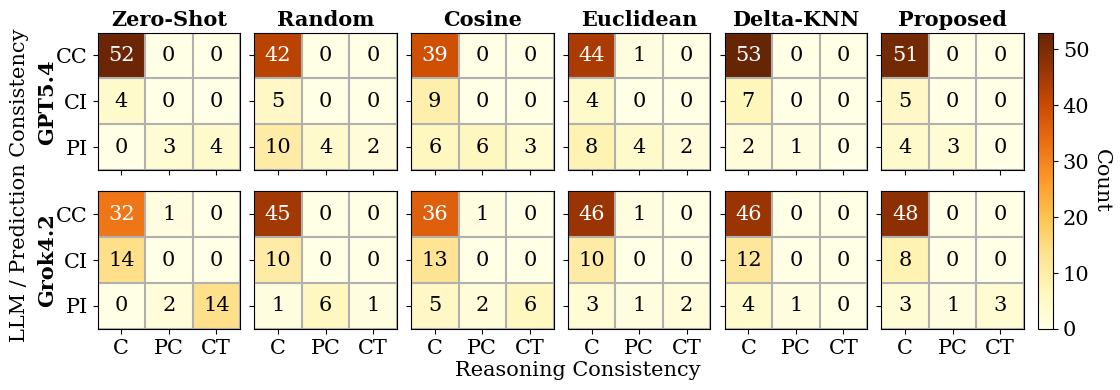

In [30]:
plot_df = combined_counts.copy()

prediction_order = [
    "Consistent Correct",
    "Consistent Incorrect",
    "Inconsistent",
]

classification_order = [
    "CONSISTENT",
    "PARTIALLY CONSISTENT",
    "CONTRADICTORY",
]

classification_labels = ["C", "PC", "CT"]
prediction_labels = ["CC", "CI", "PI"]

vmax = plot_df["count"].max()


# ---------------------------------------------------------
# Dynamic figure dimensions
# ---------------------------------------------------------

n_models = len(MODEL_ORDER)
n_methods = len(METHOD_ORDER)

# Increase these if you want larger individual heatmaps
width_per_method = 2.0
height_per_model = 2.0

fig_width = width_per_method * n_methods
fig_height = height_per_model * n_models

fig, axes = plt.subplots(
    n_models,
    n_methods,
    figsize=(
        fig_width,
        fig_height,
    ),
    sharex=True,
    sharey=True,
    squeeze=False,
)


# ---------------------------------------------------------
# Create heatmaps
# ---------------------------------------------------------

for row_idx, model in enumerate(MODEL_ORDER):

    for col_idx, method in enumerate(METHOD_ORDER):

        ax = axes[
            row_idx,
            col_idx,
        ]

        subset = plot_df[
            (plot_df["model"] == model)
            & (plot_df["method"] == method)
        ]

        # -------------------------------------------------
        # Create 3 x 3 matrix
        # -------------------------------------------------

        matrix = (
            subset
            .pivot_table(
                index="prediction_status",
                columns="classification",
                values="count",
                aggfunc="sum",
                fill_value=0,
            )
            .reindex(
                index=prediction_order,
                columns=classification_order,
                fill_value=0,
            )
        )

        values = matrix.values

        # -------------------------------------------------
        # Heatmap
        # -------------------------------------------------

        im = ax.imshow(
            values,
            cmap="YlOrBr",
            vmin=0,
            vmax=vmax,
            aspect="auto",
        )

        # -------------------------------------------------
        # Cell counts
        # -------------------------------------------------

        for i in range(values.shape[0]):

            for j in range(values.shape[1]):

                value = values[i, j]

                text_color = (
                    "white"
                    if value > vmax * 0.5
                    else "black"
                )

                ax.text(
                    j,
                    i,
                    f"{int(value)}",
                    ha="center",
                    va="center",
                    color=text_color,
                    fontsize=FONT_SIZE,
                )

        # -------------------------------------------------
        # Method titles
        # Only display above first row
        # -------------------------------------------------

        if row_idx == 0:

            ax.set_title(
                METHOD_LABELS.get(
                    method,
                    method,
                ),
                fontsize=FONT_SIZE,
                fontweight="bold",
                pad=5,
            )

        # -------------------------------------------------
        # X-axis labels
        # -------------------------------------------------

        ax.set_xticks(
            range(
                len(classification_labels)
            )
        )

        ax.set_xticklabels(
            classification_labels,
            fontsize=FONT_SIZE,
        )

        # -------------------------------------------------
        # Y-axis labels
        # -------------------------------------------------

        ax.set_yticks(
            range(
                len(prediction_labels)
            )
        )

        ax.set_yticklabels(
            prediction_labels,
            fontsize=FONT_SIZE,
        )

        # -------------------------------------------------
        # Grid between cells
        # -------------------------------------------------

        ax.set_xticks(
            np.arange(
                -0.5,
                len(classification_labels),
                1,
            ),
            minor=True,
        )

        ax.set_yticks(
            np.arange(
                -0.5,
                len(prediction_labels),
                1,
            ),
            minor=True,
        )

        ax.grid(
            which="minor",
            linewidth=1.5,
        )

        ax.tick_params(
            which="minor",
            bottom=False,
            left=False,
        )


# ---------------------------------------------------------
# Model / panel labels
# ---------------------------------------------------------

for row_idx, model in enumerate(MODEL_ORDER):

    axes[row_idx, 0].text(
        -0.35,
        0.5,
        MODEL_LABELS.get(
            model,
            model,
        ),
        transform=axes[row_idx, 0].transAxes,
        ha="center",
        va="center",
        rotation=90,
        fontsize=FONT_SIZE,
        fontweight="bold",
    )


# ---------------------------------------------------------
# Shared axis labels
# ---------------------------------------------------------

fig.text(
    0.035,
    0.5,
    "LLM / Prediction Consistency",
    va="center",
    ha="center",
    rotation="vertical",
    fontsize=FONT_SIZE,
)

fig.text(
    0.5,
    0.035,
    "Reasoning Consistency",
    ha="center",
    va="center",
    fontsize=FONT_SIZE,
)


# ---------------------------------------------------------
# Dynamic layout
# ---------------------------------------------------------

plt.subplots_adjust(
    left=0.10,
    right=0.90,
    bottom=0.14,
    top=0.88,
    wspace=0.10,
    hspace=0.15,
)


# ---------------------------------------------------------
# Shared colorbar
# ---------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=axes.ravel().tolist(),
    fraction=0.02,
    pad=0.015,
)

cbar.set_label(
    "Count",
    rotation=270,
    labelpad=15,
    fontsize=FONT_SIZE,
)

cbar.ax.tick_params(
    labelsize=FONT_SIZE
)


# ---------------------------------------------------------
# Save
# ---------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "Figure_2.pdf",
    format="pdf",
    bbox_inches="tight",
)

plt.show()

## 2. Brain Region Validity
For each model and example-selection method, this analysis measures how frequently mapped brain regions are mentioned across subjects and runs. Age is excluded because it is not an anatomical region.

In [31]:
ATOMIC_CLAIMS_DIR = REASONING_DIR / "Atomic_claims"
REGION_MAPPING_FILE = REASONING_DIR / "brain_region_mapping.csv"

REASONING_CLAIMS_CSV = EVALUATION_DIR / "reasoning_claims.csv"

# ------------------------------------------------------------
# Process all models, methods, and runs
# ------------------------------------------------------------

create_reasoning_claims(
    reasoning_dir=ATOMIC_CLAIMS_DIR,
    mapping_file=REGION_MAPPING_FILE,
    test_file=DATA_SPLIT_DIR / "test.csv",
    output_file=REASONING_CLAIMS_CSV,
)


# ------------------------------------------------------------
# Load combined output
# ------------------------------------------------------------

reasoning_df = pd.read_csv(
    REASONING_CLAIMS_CSV
)

In [32]:
bio_df = reasoning_df[["model","method","run", "subject", "component_region"]]
bio_df = bio_df.drop_duplicates().reset_index(drop=True)
bio_df = bio_df[bio_df["component_region"] != "Age"]

In [33]:
region_mentions = (bio_df[["model", "method", "run", "subject", "component_region"]]
    .dropna(subset=["component_region"])
    .drop_duplicates(subset=["model", "method", "run", "subject", "component_region"]))

run_totals = (bio_df[["model", "method", "run", "subject"]]
    .drop_duplicates()
    .groupby(["model", "method", "run"])
    .size()
    .reset_index(name="total_subjects"))

region_counts = (region_mentions
    .groupby( ["model", "method", "run", "component_region"])
    .size()
    .reset_index(name="mention_count"))

region_percentage_run = region_counts.merge(run_totals, on=["model", "method", "run"], how="left")
region_percentage_run["percentage"] = (region_percentage_run["mention_count"] / region_percentage_run["total_subjects"] * 100)

region_percentage = (region_percentage_run
    .groupby(["model", "method", "component_region"],as_index=False)
    .agg(percentage=("percentage", "mean")))

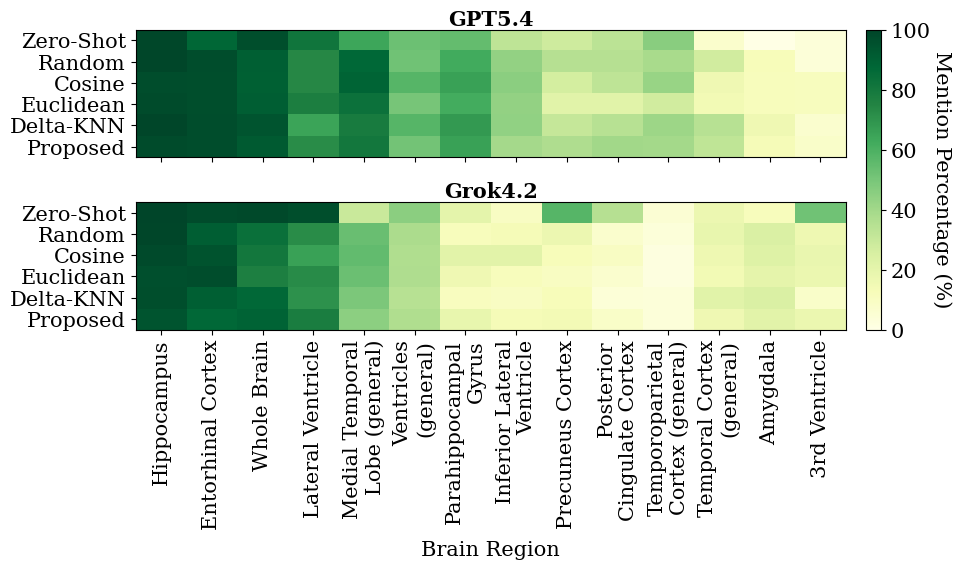

In [34]:
region_percentage["component_region"] = (region_percentage["component_region"]
    .replace({"Brain-to-ICV Ratio": "Whole Brain"}))

model_region_mean = (region_percentage
    .groupby(["model", "component_region"],as_index=False)["percentage"]
    .mean())

top_regions_by_model = {}
for model in MODEL_ORDER:

    top_regions = (model_region_mean[model_region_mean["model"] == model]
        .nlargest(10,"percentage")["component_region"]
        .tolist())

    top_regions_by_model[model] = top_regions

region_union = set()

for regions in top_regions_by_model.values():
    region_union.update(regions)

region_union = list(region_union)

region_order = (region_percentage[region_percentage["component_region"].isin(region_union)]
    .groupby("component_region")["percentage"]
    .mean()
    .sort_values(ascending=False)
    .index
    .tolist())

fig, axes = plt.subplots(2,1,figsize=(10, 5),sharex=True)

for idx, (ax, model) in enumerate(zip(axes, MODEL_ORDER)):

    model_df = region_percentage[region_percentage["model"] == model]

    matrix = model_df.pivot(index="method", columns="component_region", values="percentage")
    matrix = matrix.reindex(index=METHOD_ORDER, columns=region_order)
    matrix = matrix.fillna(0)

    im = ax.imshow(matrix.values, aspect="auto", cmap="YlGn", vmin=0, vmax=100)

    ax.set_yticks(np.arange(len(METHOD_ORDER)))
    ax.set_yticklabels([METHOD_LABELS[m] for m in METHOD_ORDER], fontsize=FONT_SIZE)
    ax.set_title(MODEL_LABELS[model], fontsize=FONT_SIZE, fontweight="bold", pad=3)

def wrap_two_lines(label, max_chars=18):

    words = label.split()

    if len(label) <= max_chars:
        return label

    best_split = 1
    best_diff = float("inf")

    for i in range(1, len(words)):

        line1 = " ".join(words[:i])
        line2 = " ".join(words[i:])

        diff = abs(len(line1) - len(line2))

        if diff < best_diff:

            best_diff = diff
            best_split = i

    return (
        " ".join(words[:best_split])
        + "\n"
        + " ".join(words[best_split:])
    )


wrapped_region_labels = [wrap_two_lines(region) for region in region_order]

axes[-1].set_xticks(np.arange(len(region_order)))
axes[-1].set_xticklabels(wrapped_region_labels, rotation=90, rotation_mode="anchor", ha="right", va="center", fontsize=FONT_SIZE)
axes[-1].set_xlabel("Brain Region", fontsize=FONT_SIZE, labelpad=8)

cbar_ax = fig.add_axes([0.89, 0.34, 0.015, 0.60])
cbar = fig.colorbar(im,cax=cbar_ax)
cbar.set_label("Mention Percentage (%)", fontsize=FONT_SIZE, rotation=270, labelpad=15)
cbar.ax.tick_params(
    labelsize=FONT_SIZE
)

plt.subplots_adjust(left=0.16, right=0.87, bottom=0.34, top=0.94, hspace=0.35)
plt.savefig(
    FIGURE_DIR / "Figure_3.pdf",
    format="pdf",
    bbox_inches="tight"
)
plt.show()

## 3. Directionality
This analysis summarizes the direction of descriptive claims for selected AD-relevant regions and links those claim directions to the LLM prediction using a Sankey diagram.

In [35]:
direction_df = reasoning_df[reasoning_df["claim_type"] == "Descriptive"]
direction_df = direction_df[["model", "method", "run", "Prediction","subject", "component_region", "direction_group"]]
direction_df = direction_df[direction_df["component_region"].isin(["Hippocampus", "Entorhinal Cortex", "Brain-to-ICV Ratio", "Lateral Ventricle"])]
direction_df["component_region"] = direction_df["component_region"].replace("Brain-to-ICV Ratio","Whole Brain")

In [36]:
sankey_df = direction_df.copy()
sankey_df = sankey_df.dropna(subset=["component_region", "direction_group", "Prediction"])
sankey_df["component_region"] = (sankey_df["component_region"].astype(str).str.strip())
sankey_df["direction_group"] = (sankey_df["direction_group"].astype(str).str.strip())
sankey_df["Prediction"] = (sankey_df["Prediction"].astype(str).str.strip().str.upper())
sankey_df["component_region"] = (sankey_df["component_region"].replace({"Brain-to-ICV Ratio": "Whole Brain"}))
sankey_df = sankey_df.drop_duplicates(subset=["subject", "model", "method", "run", "component_region", "direction_group", "Prediction"])

preferred_direction_order = ["Reduced", "Increased", "Atrophic", "Asymmetry", "Preserved"]

available_directions = set(sankey_df["direction_group"].unique())

directions = [d for d in preferred_direction_order if d in available_directions]
directions += sorted(available_directions - set(directions))

predictions = [p for p in ["AD", "CN"] if p in sankey_df["Prediction"].unique()]

region_direction = (sankey_df.groupby(["component_region", "direction_group", "Prediction"]).size().reset_index(name="count"))
direction_prediction = (sankey_df.groupby(["direction_group", "Prediction"]).size().reset_index(name="count"))

region_nodes = [f"Region: {r}" for r in sankey_df["component_region"].unique()]
direction_nodes = [f"Direction: {d}" for d in directions]
prediction_nodes = [f"Prediction: {p}" for p in predictions]

nodes = (region_nodes + direction_nodes + prediction_nodes)
node_index = {node: i for i, node in enumerate(nodes)}

display_labels = (sankey_df["component_region"].unique().tolist() + directions + predictions)

sources = []
targets = []
values = []
link_colors = []

for _, row in region_direction.iterrows():

    source = f"Region: {row['component_region']}"
    target = f"Direction: {row['direction_group']}"

    if source not in node_index or target not in node_index:
        continue

    sources.append(node_index[source])
    targets.append(node_index[target])
    values.append(row["count"])

    if row["Prediction"] == "AD":
        link_colors.append("rgba(220,70,70,0.45)")
    elif row["Prediction"] == "CN":
        link_colors.append("rgba(60,110,210,0.45)")
    else:
        link_colors.append("rgba(150,150,150,0.35)")

for _, row in direction_prediction.iterrows():

    source = f"Direction: {row['direction_group']}"
    target = f"Prediction: {row['Prediction']}"

    if source not in node_index or target not in node_index:
        continue

    sources.append(node_index[source])
    targets.append(node_index[target])
    values.append(row["count"])

    if row["Prediction"] == "AD":
        link_colors.append("rgba(220,70,70,0.45)")
    elif row["Prediction"] == "CN":
        link_colors.append("rgba(60,110,210,0.45)")
    else:
        link_colors.append("rgba(150,150,150,0.35)")

region_x = 0.08
direction_x = 0.42
prediction_x = 0.76

node_x = (
    [region_x] * len(sankey_df["component_region"].unique())
    + [direction_x] * len(directions)
    + [prediction_x] * len(predictions)
)

region_y = [0.12, 0.35, 0.64, 0.89]

direction_y = [0.19, 0.45, 0.58, 0.63, 0.82]
direction_y = direction_y[:len(directions)]

prediction_y = [0.25, 0.78]

node_y = (region_y + direction_y + prediction_y)

node_colors = []

# Regions
node_colors += ["rgba(190,190,190,1)" for _ in sankey_df["component_region"].unique()]

# Directions
node_colors += ["rgba(190,190,190,1)" for _ in directions]

for prediction in predictions:
    if prediction == "AD":
        node_colors.append("rgba(220,45,45,1)")
    elif prediction == "CN":
        node_colors.append("rgba(45,95,210,1)")
    else:
        node_colors.append("rgba(150,150,150,1)")


fig = go.Figure(
    data=[go.Sankey(
        arrangement="fixed",
        textfont=dict(
                family="DejaVu Serif",
                size=FONT_SIZE,
                color="black"
            ),
        node=dict(
            pad=10,
            thickness=16,
            line=dict(color="rgba(80,80,80,0.7)",width=0.7),
            label=display_labels,
            color=node_colors,
            x=node_x,
            y=node_y,
            hovertemplate=("%{label}<br> Count: %{value} <extra></extra>")),
        link=dict(
            source=sources,
            target=targets,
            value=values,
            color=link_colors,
            hovertemplate=("Count: %{value} <extra></extra>")))])

fig.add_annotation(
    x=0.01,
    y=1.06,
    text="<b>Brain Region</b>",
    showarrow=False,
    xref="paper",
    yref="paper",
    font=dict(family="DejaVu Serif", size=FONT_SIZE, color="black"))

fig.add_annotation(
    x=0.42,
    y=1.06,
    text="<b>Direction</b>",
    showarrow=False,
    xref="paper",
    yref="paper",
    font=dict(family="DejaVu Serif", size=FONT_SIZE, color="black"))

fig.add_annotation(
    x=0.8,
    y=1.06,
    text="<b>Prediction</b>",
    showarrow=False,
    xref="paper",
    yref="paper",
    font=dict(family="DejaVu Serif", size=FONT_SIZE, color="black"))

fig.update_layout(
    width=1000,
    height=500,
    font=dict(family="DejaVu Serif", size=FONT_SIZE, color="black"),
    margin=dict(l=20, r=20, t=30, b=8), paper_bgcolor="white",
    plot_bgcolor="white")

fig.write_image(
    str(FIGURE_DIR / "Figure_4.png"),
    format="png",
    width=1000,
    height=500
)

fig.show()

## 4. Utility of In-Context Examples
A subject is counted as explicitly using in-context examples when at least one extracted reasoning claim contains language referring to examples, cases, or reference values/ranges associated with the demonstrations.

In [37]:
ICL_df = reasoning_df[["model", "method", "run", "subject", "claim"]]
ICL_df = ICL_df[ICL_df["method"] != "zero_shot"]

In [38]:
icl_analysis = ICL_df.copy()

def mentions_icl_example(claim):

    if pd.isna(claim):
        return False

    text = str(claim).strip().lower()

    if text == "":
        return False

    patterns = [

        # Example / examples
        r"\bexample\b",
        r"\bexamples\b",

        # Ex1, Ex 1, Ex.1, Ex. 1
        r"\bex\.?\s*\d+\b",

        # Explicit provided/reference cases
        r"\bprovided\s+cases?\b",

        # AD cases / Alzheimer's cases
        r"\bad\s+cases?\b",
        r"\balzheimer'?s\s+cases?\b",

        # Non-AD / Non-Alzheimer's cases
        r"\bnon[-\s]?ad\s+cases?\b",
        r"\bnon[-\s]?alzheimer'?s\s+cases?\b",

        # Reference values/ranges used from demonstrations
        r"\breference\s+.*\b(?:volume|volumes|value|values|range|ranges|thickness)\b",
    ]

    return any(
        re.search(pattern, text, flags=re.IGNORECASE)
        for pattern in patterns
    )


# Apply to every claim
icl_analysis["example_mentioned"] = (icl_analysis["claim"].apply(mentions_icl_example))

In [39]:
subject_example_usage = (icl_analysis
    .groupby(["model", "method", "subject"], as_index=False)
    .agg(example_mentioned=("example_mentioned", "max")))

subject_example_usage["example_mentioned"] = (subject_example_usage["example_mentioned"]
    .astype(int))

In [40]:
icl_percentage = (subject_example_usage
    .groupby(["model","method"],as_index=False)
    .agg(total_subjects=("subject","nunique"), subjects_with_example=("example_mentioned","sum")))

icl_percentage["percentage"] = (icl_percentage["subjects_with_example"] / icl_percentage["total_subjects"] * 100)
icl_percentage["percentage"] = (icl_percentage["percentage"].round(2))

In [41]:
model_method_summary = (
    icl_percentage[
        [
            "model",
            "method",
            "percentage",
        ]
    ]
    .rename(
        columns={
            "percentage":
                "mean_percentage"
        }
    )
    .copy()
)

model_method_summary["model"] = pd.Categorical(
    model_method_summary["model"],
    categories=MODEL_ORDER,
    ordered=True,
)

model_method_summary["method"] = pd.Categorical(
    model_method_summary["method"],
    categories=METHOD_ORDER,
    ordered=True,
)

model_method_summary = (
    model_method_summary
    .sort_values(
        [
            "model",
            "method",
        ]
    )
    .reset_index(
        drop=True
    )
)

display(
    model_method_summary
)


,model,method,mean_percentage
0,gpt-5.4,random,47.62
1,gpt-5.4,cosine,41.27
2,gpt-5.4,euclidean,53.97
3,gpt-5.4,delta_knn,36.51
4,gpt-5.4,lr_weighted_xgboost_path_gain,34.92
5,grok-4.20-reasoning,random,100.00
6,grok-4.20-reasoning,cosine,100.00
7,grok-4.20-reasoning,euclidean,100.00
8,grok-4.20-reasoning,delta_knn,100.00
9,grok-4.20-reasoning,lr_weighted_xgboost_path_gain,100.00


In [42]:
llm_summary = (
    model_method_summary
    .groupby("model", as_index=False)
    .agg(
        mean_percentage=("mean_percentage", "mean"),
        std_percentage=("mean_percentage", "std")
    )
)

llm_summary["model"] = pd.Categorical(
    llm_summary["model"],
    categories=MODEL_ORDER,
    ordered=True
)

llm_summary = (
    llm_summary
    .sort_values("model")
    .reset_index(drop=True)
)

/tmp/ipykernel_21470/1605723855.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  model_method_summary


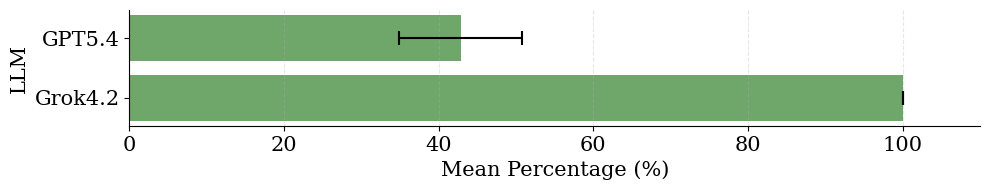

In [43]:

fig, ax = plt.subplots(figsize=(10, 2))

y = np.array([0, 0.65])

bars = ax.barh(
    y,
    llm_summary["mean_percentage"],
    xerr=llm_summary["std_percentage"],
    height=0.5, color="#6FA66A",
    capsize=5,
    error_kw={
        "elinewidth": 1.5,
        "capthick": 1.5
    }
)

# ---------------------------------------------------------
# Y-axis
# ---------------------------------------------------------

ax.set_yticks(y)

ax.set_yticklabels(
    [MODEL_LABELS[m] for m in MODEL_ORDER],
    fontsize=FONT_SIZE
)

ax.set_ylabel(
    "LLM",
    fontsize=FONT_SIZE
)

# ---------------------------------------------------------
# X-axis
# ---------------------------------------------------------

ax.set_xlabel(
    "Mean Percentage (%)",
    fontsize=FONT_SIZE
)

ax.tick_params(
    axis="both",
    labelsize=FONT_SIZE
)

ax.set_xlim(0, 110)

# GPT5.4 first/top
ax.invert_yaxis()

# ---------------------------------------------------------
# Appearance
# ---------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

# ---------------------------------------------------------
# Layout
# ---------------------------------------------------------

plt.tight_layout()

# ---------------------------------------------------------
# Save PDF
# ---------------------------------------------------------

plt.savefig(
    FIGURE_DIR / "Figure_6.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

## 5. Claim Direction change
For subjects where the prediction change across the example selection method the direction of the same claim has to be changed to align with the prediction. This means that the reasoning has also been impacted by the given examples, since that is the only thing that is different b/w the methods.

In [44]:
change_claim_df = reasoning_df[(reasoning_df["claim_type"].isin(["Descriptive", "Interpretive", "Comparative"])) & (reasoning_df["run"] == 1) & (reasoning_df["component_region"] != "Age")]
change_claim_df = change_claim_df[["model", "method", "subject", "True_Label", "Prediction","component_region", "direction_group"]]
change_claim_df = change_claim_df.dropna(subset=["component_region"])
change_claim_df = change_claim_df.dropna(subset=["direction_group"])
change_claim_df = change_claim_df[~change_claim_df["component_region"].str.contains(r"\(unspecified\)|\(general\)", case=False, na=False,)].reset_index(drop=True)
change_claim_df = change_claim_df[change_claim_df["subject"] == "114_S_0173"]

In [45]:
change_claim_df[change_claim_df["method"] == "lr_weighted_xgboost_path_gain"]

,model,method,subject,True_Label,Prediction,component_region,direction_group
1358,gpt-5.4,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Entorhinal Cortex,Preserved
1359,gpt-5.4,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Hippocampus,Preserved
1360,gpt-5.4,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Hippocampus,Preserved
1361,gpt-5.4,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Lateral Ventricle,Increased
1362,gpt-5.4,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Parahippocampal Gyrus,Preserved
3412,grok-4.20-reasoning,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Brain-to-ICV Ratio,Preserved
3413,grok-4.20-reasoning,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Entorhinal Cortex,Increased
3414,grok-4.20-reasoning,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Entorhinal Cortex,Reduced
3415,grok-4.20-reasoning,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Hippocampus,Increased
3416,grok-4.20-reasoning,lr_weighted_xgboost_path_gain,114_S_0173,CN,CN,Hippocampus,Reduced


In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# =========================================================
# INPUT
# ---------------------------------------------------------
# subject_df should already contain only ONE subject
# with columns:
# model, method, subject, True_Label, Prediction,
# component_region, direction_group
# =========================================================

df = change_claim_df.copy()


# =========================================================
# CLEAN METHOD NAMES (optional)
# =========================================================

method_label_map = {
    "zero_shot": "Zero-shot",
    "random": "Random",
    "cosine": "Cosine",
    "euclidean": "Euclidean",
    "delta_knn": "Delta-kNN",
    "lr_weighted_xgboost_path_gain": "Proposed",
}

df["method_display"] = df["method"].map(method_label_map).fillna(df["method"])


# =========================================================
# MAP DIRECTION TO SCORE
# +1 = supports AD
# -1 = supports CN
#  0 = neutral / unclear
# =========================================================

VENTRICULAR_REGIONS = {
    "3rd Ventricle",
    "Lateral Ventricle",
    "Inferior Lateral Ventricle",
    "CSF Spaces",
}

def get_direction_score(region, direction):

    if pd.isna(region) or pd.isna(direction):
        return 0

    region = str(region).strip()
    direction = str(direction).strip()

    # Neutral / not directionally useful
    if direction == "Asymmetry":
        return 0

    # Ventricles / CSF
    if region in VENTRICULAR_REGIONS:
        if direction == "Increased":
            return 1
        elif direction in {"Reduced", "Preserved"}:
            return -1
        else:
            return 0

    # Brain-to-ICV Ratio
    if region == "Brain-to-ICV Ratio":
        if direction in {"Reduced", "Atrophic"}:
            return 1
        elif direction in {"Preserved", "Increased"}:
            return -1
        else:
            return 0

    # Other brain regions
    if direction in {"Reduced", "Atrophic"}:
        return 1
    elif direction in {"Preserved", "Increased"}:
        return -1
    else:
        return 0


df["direction_score"] = df.apply(
    lambda row: get_direction_score(
        row["component_region"],
        row["direction_group"]
    ),
    axis=1,
)


# =========================================================
# COLLAPSE DUPLICATES WITHIN SAME MODEL/METHOD/REGION
# If all claims agree -> keep +1 or -1
# If conflicting -> 0
# =========================================================

# =========================================================
# COLLAPSE MULTIPLE CLAIMS FOR SAME REGION
#
# Rule:
#
# Prediction = AD:
#   if at least one +1 exists -> +1
#   otherwise if -1 exists   -> -1
#   otherwise                -> 0
#
# Prediction = CN:
#   if at least one -1 exists -> -1
#   otherwise if +1 exists    -> +1
#   otherwise                 -> 0
# =========================================================

def collapse_scores_with_prediction(group):

    prediction = group["Prediction"].iloc[0]

    scores = (
        group["direction_score"]
        .dropna()
        .astype(int)
        .tolist()
    )

    # Remove neutral values when checking direction
    non_zero_scores = [
        score
        for score in scores
        if score != 0
    ]

    # No directional evidence
    if len(non_zero_scores) == 0:
        return 0


    # -----------------------------------------------------
    # Final prediction = AD
    # -----------------------------------------------------

    if prediction == "AD":

        # At least one claim supports AD
        if 1 in non_zero_scores:
            return 1

        # Otherwise claims only support CN
        if -1 in non_zero_scores:
            return -1


    # -----------------------------------------------------
    # Final prediction = CN
    # -----------------------------------------------------

    elif prediction == "CN":

        # At least one claim supports CN
        if -1 in non_zero_scores:
            return -1

        # Otherwise claims only support AD
        if 1 in non_zero_scores:
            return 1


    return 0

collapsed_df = (
    df.groupby(
        [
            "model",
            "subject",
            "method_display",
            "component_region",
        ],
        group_keys=False,
    )
    .apply(
        collapse_scores_with_prediction,
        include_groups=False,
    )
    .reset_index(
        name="direction_score"
    )
)
# =========================================================
# GET PREDICTION FOR EACH MODEL/METHOD
# =========================================================

pred_df = (
    df[
        [
            "model",
            "subject",
            "method_display",
            "Prediction",
        ]
    ]
    .drop_duplicates()
    .copy()
)


# =========================================================
# ORDERING
# =========================================================

method_order = [
    "Zero-shot",
    "Random",
    "Cosine",
    "Euclidean",
    "Delta-kNN",
    "Proposed",
]

region_order = sorted(collapsed_df["component_region"].unique())


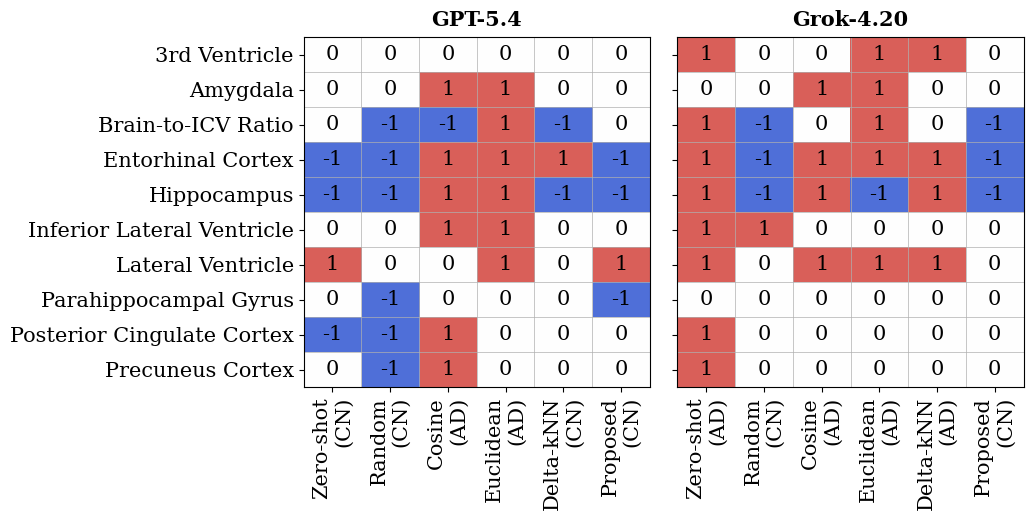

In [47]:

models = collapsed_df["model"].drop_duplicates().tolist()
n_models = len(models)

fig, axes = plt.subplots(
    1,
    n_models,
    figsize=(10, 5),
    squeeze=False,
    sharey=True,
)

for idx, model in enumerate(models):

    ax = axes[0, idx]

    model_df = collapsed_df[
        collapsed_df["model"] == model
    ].copy()

    # -----------------------------------------------------
    # Pivot to matrix
    # -----------------------------------------------------

    matrix_df = (
        model_df.pivot_table(
            index="component_region",
            columns="method_display",
            values="direction_score",
            aggfunc="first",
            fill_value=0,
        )
        .reindex(index=region_order)
    )

    available_methods = [
        m for m in method_order
        if m in matrix_df.columns
    ]

    matrix_df = (
        matrix_df
        .reindex(
            columns=available_methods
        )
        .fillna(0)
        .astype(int)
    )

    values = matrix_df.values

    # -----------------------------------------------------
    # Heatmap
    # -----------------------------------------------------

    soft_cmap = LinearSegmentedColormap.from_list(
        "soft_red_blue",
        [
            "#4F6FD8",  # soft blue
            "#FFFFFF",  # white
            "#D95F59",  # soft red
        ]
    )

    im = ax.imshow(
        values,
        aspect="auto",
        vmin=-1,
        vmax=1,
        cmap=soft_cmap,
    )

    # -----------------------------------------------------
    # Cell annotations
    # -----------------------------------------------------

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):

            val = int(values[i, j])

            ax.text(
                j,
                i,
                f"{val}",
                ha="center",
                va="center",
                fontsize=FONT_SIZE,
            )

    # -----------------------------------------------------
    # Prediction labels
    # -----------------------------------------------------

    model_pred_df = (
        pred_df[
            pred_df["model"] == model
        ]
        .drop_duplicates()
    )

    pred_lookup = {
        row["method_display"]: row["Prediction"]
        for _, row in model_pred_df.iterrows()
    }

    col_labels = [
        f"{m}\n({pred_lookup.get(m, '-')})"
        for m in available_methods
    ]

    ax.set_xticks(
        range(len(available_methods))
    )

    ax.set_xticklabels(
        col_labels,
        rotation=90,
        ha="right", va = "center", rotation_mode = "anchor",
        fontsize=FONT_SIZE,
    )

    ax.set_yticks(
        range(len(matrix_df.index))
    )

    ax.set_yticklabels(
        matrix_df.index,
        fontsize=FONT_SIZE,
    )

    # -----------------------------------------------------
    # Cleaner model labels
    # -----------------------------------------------------

    model_title_map = {
        "gpt-5.4": "GPT-5.4",
        "grok-4.20-reasoning": "Grok-4.20",
    }

    ax.set_title(
        model_title_map.get(
            model,
            model,
        ),
        fontsize=FONT_SIZE,
        fontweight="bold",
        pad=8,
    )

    # -----------------------------------------------------
    # Grid
    # -----------------------------------------------------

    ax.set_xticks(
        np.arange(
            -0.5,
            len(available_methods),
            1
        ),
        minor=True,
    )

    ax.set_yticks(
        np.arange(
            -0.5,
            len(matrix_df.index),
            1
        ),
        minor=True,
    )

    ax.grid(
        which="minor",
        linewidth=0.5,
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )

    ax.tick_params(
        axis="both",
        labelsize=FONT_SIZE,
    )


# =========================================================
# SHARED TITLE
# =========================================================

subject = df["subject"].iloc[0]
true_label = df["True_Label"].iloc[0]

# fig.suptitle(
#     f"Subject: {subject} | True label: {true_label}",
#     fontsize=FONT_SIZE,
#     fontweight="bold",
#     y=0.98,
# )


# =========================================================
# SHARED COLORBAR
# =========================================================

# cax = fig.add_axes([
#     0.89,   # x position
#     0.18,   # y position
#     0.012,  # width
#     0.7,   # height
# ])

# cbar = fig.colorbar(
#     im,
#     cax=cax,
# )

# cbar.set_ticks(
#     [-1, 0, 1]
# )

# cbar.set_ticklabels([
#     "CN",
#     "No",
#     "AD",
# ])

# cbar.ax.tick_params(
#     labelsize=FONT_SIZE
# )


# =========================================================
# LAYOUT
# =========================================================

plt.subplots_adjust(
    left=0.16,
    right=0.88,
    top=0.88,
    bottom=0.18,
    wspace=0.08,
)

plt.savefig(
    FIGURE_DIR / "Figure_7.pdf",
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.01
)

plt.show()